<a href="https://colab.research.google.com/github/sharakhaplan/All-Aml-Leukemia-Subtype-Classification-Using-Gene-Expression-Data/blob/main/Classification_of_ALL_and_AML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

for kok_dizin, klasorler, dosyalar in os.walk('/content/drive/MyDrive'):
    for dosya in dosyalar:
        if dosya.lower().endswith(('.csv', '.xlsx')):
            print(os.path.join(kok_dizin, dosya))

/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/actual.csv
/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_independent.csv
/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_train.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

#grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 10

print("Kütüphaneler Yüklendi,Grafik Ayarları oluşturuldu :)")

Kütüphaneler Yüklendi,Grafik Ayarları oluşturuldu :)


In [9]:
# Dosyaları yükleme
train_raw = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_train.csv")
test_raw = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_independent.csv")
actual = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/actual.csv")

In [8]:
# Biyolojik 'call' (P,A,M) sütunlarını temizleme
train_cols = [c for c in train_raw.columns if "call" not in c.lower()]
test_cols = [c for c in test_raw.columns if "call" not in c.lower()]

train_clean = train_raw[train_cols]
test_clean = test_raw[test_cols]

In [10]:
# Train ve Independent verilerini gen isimleri üzerinden birleştirme
df_merged = pd.merge(train_clean, test_clean, on=['Gene Description','Gene Accession Number'])
df_merged.set_index(['Gene Accession Number', 'Gene Description'], inplace=True)

In [12]:
# Sütun isimlerini hasta ID (integer) olarak düzenleme
clean_patient_ids = [int(c) for c in df_merged.columns]
df_merged.columns = clean_patient_ids

In [13]:
# Matrisi çevirme (Satırlar: Hastalar, Sütunlar: Genler)
X_raw = df_merged.T.sort_index()

In [14]:
# actual.csv ile hasta etiketlerini eşleştirme
actual['patient'] = actual['patient'].astype(int)
actual.set_index('patient', inplace=True)
y_labels = actual.loc[X_raw.index, 'cancer']

In [15]:
# Özet bilgileri ekrana yazırma
print(f"================ VERİ ÖZETİ ================")
print(f"Toplam Hasta Sayısı (n): {X_raw.shape[0]}")
print(f"Toplam Gen Sayısı (p): {X_raw.shape[1]}")
print(f"Eksik (NaN) Değer Sayısı: {X_raw.isna().sum().sum()}")
print("\nSınıf Dağılımı:")
print(y_labels.value_counts())
print("\nYüzdesel Dağılım:")
print((y_labels.value_counts(normalize=True) * 100).round(2))




================ VERİ ÖZETİ ================
Toplam Hasta Sayısı (n): 72
Toplam Gen Sayısı (p): 7129
Eksik (NaN) Değer Sayısı: 0

Sınıf Dağılımı:
cancer
ALL    47
AML    25
Name: count, dtype: int64

Yüzdesel Dağılım:
cancer
ALL    65.28
AML    34.72
Name: proportion, dtype: float64


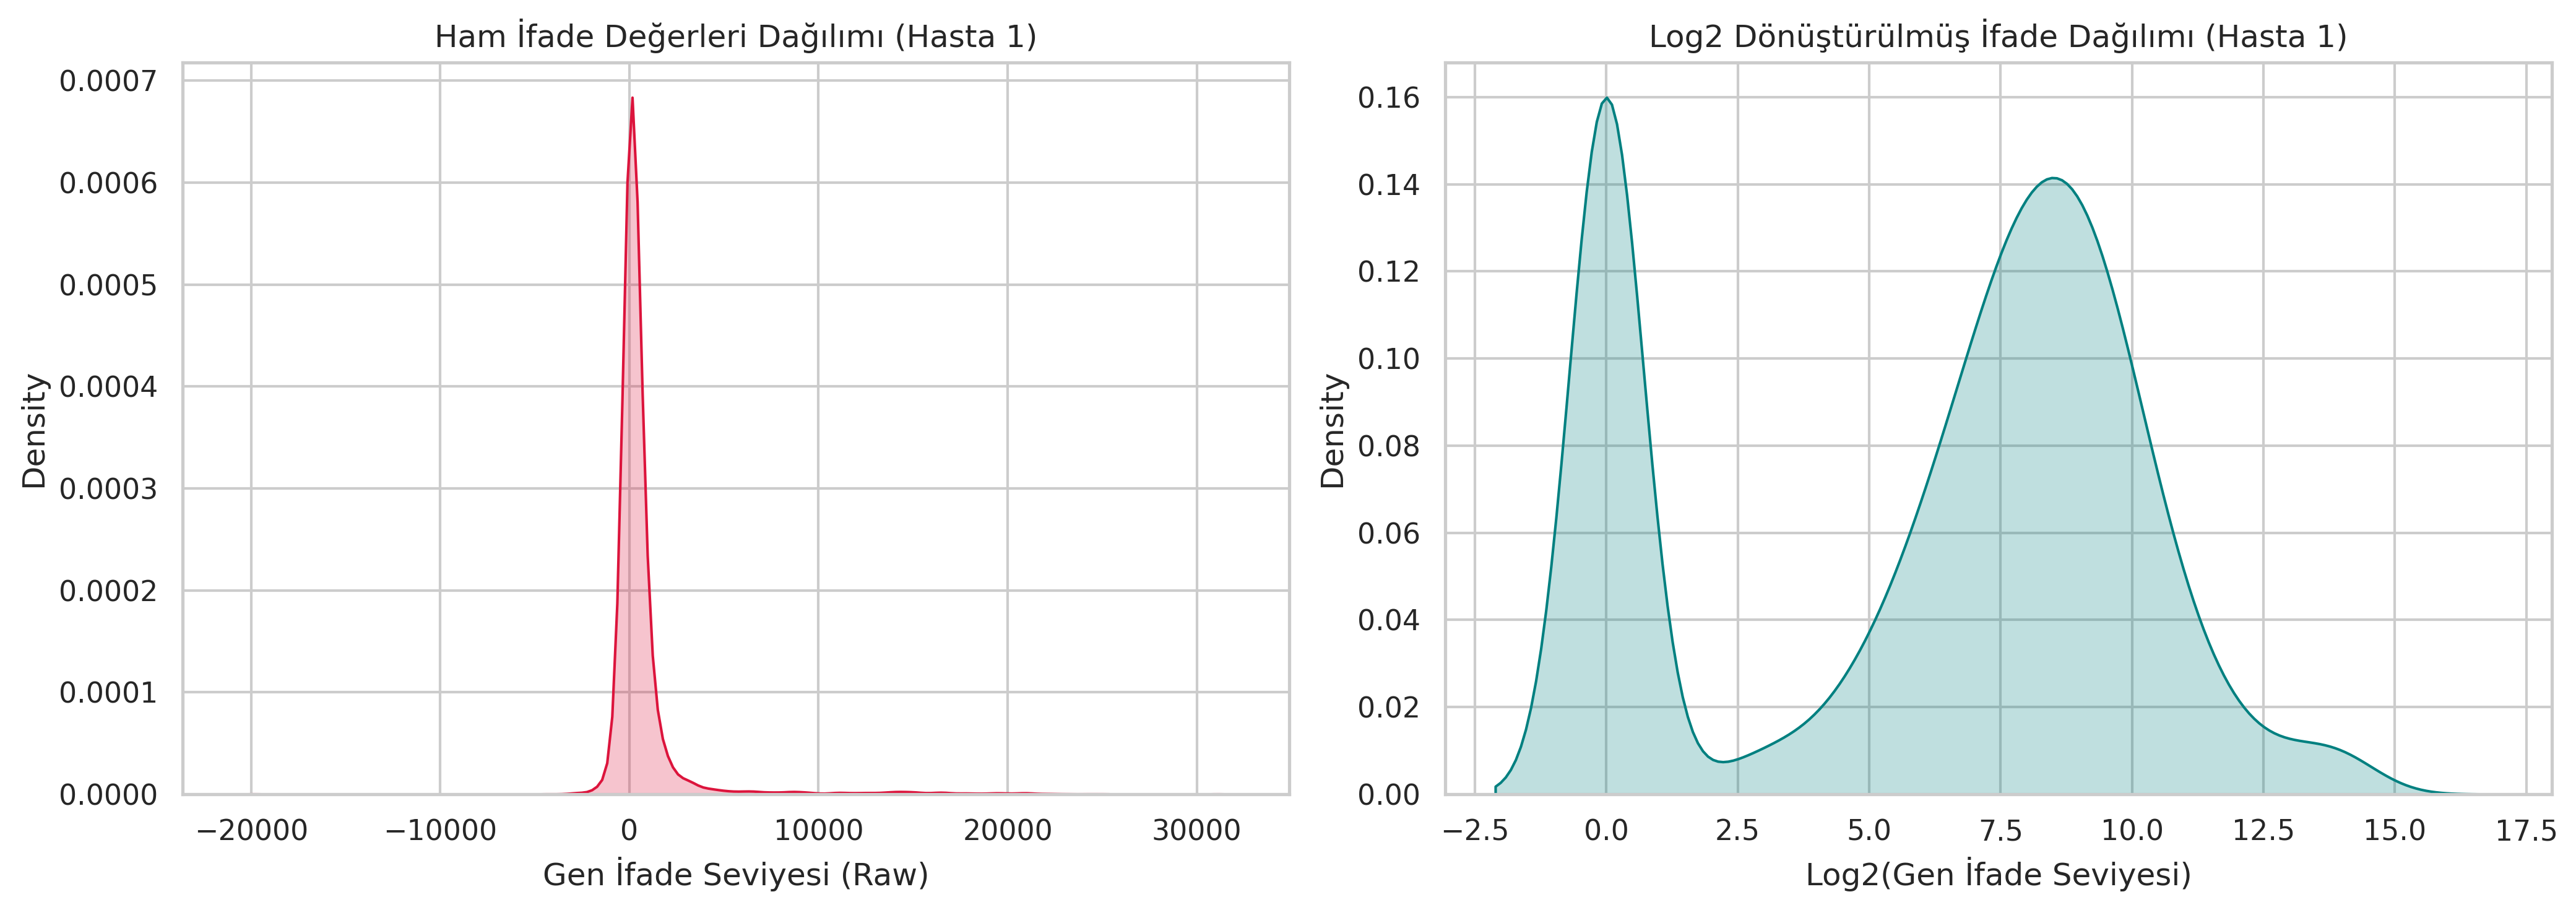

✅ Log2 dönüşümü yapıldı ve '1_log2_transformation.png' kaydedildi!


In [17]:
# Negatif ve sıfır değerleri biyolojik taban değer olan 1'e sabitleme (Thresholding)
X_floored = X_raw.clip(lower=1)

# Log2 Dönüşümü
X_log2 = np.log2(X_floored)

# Ham Veri vs Log2 Dağılım Grafiği
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(X_raw.iloc[0], ax=axes[0], color='crimson', fill=True)
axes[0].set_title("Ham İfade Değerleri Dağılımı (Hasta 1)")
axes[0].set_xlabel("Gen İfade Seviyesi (Raw)")
sns.kdeplot(X_log2.iloc[0], ax=axes[1], color='teal', fill=True)
axes[1].set_title("Log2 Dönüştürülmüş İfade Dağılımı (Hasta 1)")
axes[1].set_xlabel("Log2(Gen İfade Seviyesi)")
plt.tight_layout()
plt.savefig("1_log2_transformation.png")
plt.show()

print("✅ Log2 dönüşümü yapıldı ve '1_log2_transformation.png' kaydedildi!")

